# 2.7b — SMO : SVM à marge souple, KKT et dualité

[Source Python](2.7b-SMO-From-Scratch.ipynb) | [Index](README.md) | [Comparaison LIBSVM](2.7c-SVM-SOTA-Comparison-CSharp.ipynb)

**Objectifs** : formuler le dual SVM, résoudre le sous-problème à deux variables, suivre biais et cache, comparer prédictions et supports, puis calculer gap et violations KKT. **Prérequis** : SVM à noyau, optimisation convexe et lecture d'une marge. **Durée indicative** : 60 minutes.

La boucle SMO, le noyau RBF et les diagnostics sont écrits en C#. Python.NET fournit le même jeu `make_moons` et le vrai `sklearn.svm.SVC`/LIBSVM. L'exécution charge Python.NET et MathNet : installer NumPy et scikit-learn dans un CPython compatible, définir `PYTHONNET_PYDLL` vers sa bibliothèque et rendre son standard library et ses `site-packages` visibles du processus .NET ; selon l'installation, configurer `PYTHONHOME` et `PYTHONPATH`. La bibliothèque seule ne sélectionne pas forcément le venv. Vérifier les imports dans l'environnement choisi avant l'exécution.

In [1]:
#r "nuget: PythonNet, 3.0.5"
#r "nuget: MathNet.Numerics, 5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text;
using System.Text.Json;
using System.Globalization;
using System.Diagnostics;
using Python.Runtime;
using MathNet.Numerics.LinearAlgebra;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
// Le pont charge le solveur LIBSVM réel et conserve le tirage NumPy partagé.
if (!PythonEngine.IsInitialized)
{
    var library = Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (string.IsNullOrWhiteSpace(library))
        throw new InvalidOperationException("Configurer PYTHONNET_PYDLL et installer NumPy et scikit-learn.");
    Runtime.PythonDLL = library;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}

double[][] Matrix(JsonElement e) => e.EnumerateArray().Select(row => row.EnumerateArray().Select(v => v.GetDouble()).ToArray()).ToArray();
double[] Vector(JsonElement e) => e.EnumerateArray().Select(v => v.GetDouble()).ToArray();
int[] Integers(JsonElement e) => e.EnumerateArray().Select(v => v.GetInt32()).ToArray();
PyModule py;
using (Py.GIL())
{
    py = Py.CreateScope();
    py.Exec(@"import json, time, numpy as np, sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
X,y0=make_moons(n_samples=200,noise=.25,random_state=42)
y=np.where(y0==0,-1.,1.)
X_tr,X_te,y_tr,y_te=train_test_split(X,y,test_size=.30,random_state=42,stratify=y)
C,gamma,tol=1.,2.,1e-3
start=time.perf_counter(); clf=SVC(C=C,kernel='rbf',gamma=gamma,tol=tol,max_iter=20000).fit(X_tr,y_tr); duration=time.perf_counter()-start
xmin,xmax=float(X[:,0].min()-.5),float(X[:,0].max()+.5)
ymin,ymax=float(X[:,1].min()-.5),float(X[:,1].max()+.5)
xx,yy=np.meshgrid(np.linspace(xmin,xmax,200),np.linspace(ymin,ymax,200))
grid=np.c_[xx.ravel(),yy.ravel()]
seed=np.random.default_rng(7); Xw=seed.normal(size=(7,3)); yw=np.where(seed.random(7)>.5,1.,-1.); aw=np.round(seed.random(7)*.5,3)
result=json.dumps(dict(train=X_tr.tolist(),test=X_te.tolist(),ytrain=y_tr.tolist(),ytest=y_te.tolist(),support=clf.support_.tolist(),dual=clf.dual_coef_[0].tolist(),bias=float(clf.intercept_[0]),test_scores=clf.decision_function(X_te).tolist(),train_scores=clf.decision_function(X_tr).tolist(),grid_scores=clf.decision_function(grid).tolist(),xmin=xmin,xmax=xmax,ymin=ymin,ymax=ymax,duration=duration,xw=Xw.tolist(),yw=yw.tolist(),aw=aw.tolist(),numpy=np.__version__,sklearn=sklearn.__version__))");
}

JsonElement Data()
{
    using (Py.GIL())
        return JsonDocument.Parse(py.Get("result").As<string>()).RootElement;
}

var data = Data();
var train = Matrix(data.GetProperty("train"));
var test = Matrix(data.GetProperty("test"));
var ytrain = Vector(data.GetProperty("ytrain"));
var ytest = Vector(data.GetProperty("ytest"));
var supportSk = Integers(data.GetProperty("support"));
var alphaSk = new double[ytrain.Length];
var signedSk = Vector(data.GetProperty("dual"));
for (int i = 0; i < supportSk.Length; i++)
    alphaSk[supportSk[i]] = Math.Abs(signedSk[i]);
Console.WriteLine($"NumPy {data.GetProperty("numpy").GetString()}, scikit-learn {data.GetProperty("sklearn").GetString()} ; train={train.Length}, test={test.Length}, C=1, gamma=2, tol=1e-3");

Installed Packages MathNet.Numerics, 5.0.0 PythonNet, 3.0.5

NumPy 2.3.5, scikit-learn 1.8.0 ; train=140, test=60, C=1, gamma=2, tol=1e-3


## 1. Le dual SVM et les conditions KKT

Pour les points `(xᵢ,yᵢ)` avec `yᵢ∈{−1,+1}`, le dual soft-margin maximise

`W(α)=Σᵢαᵢ−½Σᵢⱼ αᵢαⱼ yᵢyⱼ K(xᵢ,xⱼ)`

sous `0≤αᵢ≤C` et `Σᵢαᵢyᵢ=0`. Bouger une seule composante briserait en général l'égalité : SMO optimise une paire à la fois en conservant sa contribution à cette somme. Le noyau RBF `K(x,z)=exp(−γ‖x−z‖²)` permet une frontière non linéaire sans construire explicitement les coordonnées de l'espace de caractéristiques.

À l'optimum exact, le score `f(x)=ΣᵢαᵢyᵢK(xᵢ,x)+b` vérifie trois régimes : `αᵢ=0` implique `yᵢf(xᵢ)≥1` ; `0<αᵢ<C` implique `yᵢf(xᵢ)=1` ; `αᵢ=C` implique `yᵢf(xᵢ)≤1`. Ce sont des conditions d'optimalité ; à tolérance finie il faut mesurer les écarts.

## 2. Noyau et prédiction

La matrice de Gram `K[i,j]` est symétrique, de diagonale 1 et, pour un noyau RBF valide, semi-définie positive. Une valeur éloignée est proche de zéro. Sa construction coûte `O(n²d)` et sa mémorisation `O(n²)` ; cette implémentation est adaptée au petit jeu étudié, pas à une promesse d'échelle illimitée.

## 3. Sous-problème à deux variables

En fixant les autres α, l'égalité impose `αᵢyᵢ+αⱼyⱼ=c`. Les bornes `[L,H]` viennent de l'intersection avec `[0,C]²`. La courbure est `η=Kᵢᵢ+Kⱼⱼ−2Kᵢⱼ`. Si `η>0`, le point stationnaire non contraint est `αⱼ + yⱼ(Eᵢ−Eⱼ)/η` ; on le **projette** dans `[L,H]`, car l'optimum contraint peut être une borne. Pour `η≤0`, on compare directement l'objectif dual aux deux bornes. Un doublon RBF peut donner `η=0` ; `η<0` ne vient pas d'un noyau PSD exact et sert ici de test arithmétique artificiel.

## 4. Choisir la paire et mettre à jour le biais

Pour chaque exemple violant le test KKT, la boucle tente d'abord le support intérieur qui maximise `|Eᵢ−Eⱼ|`. Si la paire échoue, elle essaie les autres indices dans l'ordre. Les deux nouveaux α respectent l'égalité ; le biais est calculé à partir d'un support intérieur si possible, sinon à partir de la moyenne des deux candidats. Tout le cache d'erreurs reçoit le déplacement du biais : l'oublier modifie les scores même si les α semblent proches.

## 5. Arrêt et limites de la mesure locale

Le résidu `rᵢ=yᵢEᵢ=yᵢf(xᵢ)−1` compare la marge au seuil 1. Une violation est examinée si `rᵢ<−tol` et `αᵢ<C`, ou si `rᵢ>tol` et `αᵢ>0`. Un pas trop petit est refusé selon `eps`, et l'algorithme termine après `max_passes` balayages sans modification. Le compteur est le nombre **d'examens d'exemples**, pas le nombre de mises à jour réussies ni le compteur LIBSVM. Ces gardes locaux ne prouvent pas automatiquement une borne sur chaque violation finale ; nous la calculons séparément.

In [2]:
public record SmoModel(double[] Alpha, double Bias, int Examinations);
public static class Smo
{
    public static double Kernel(double[] x, double[] y, double gamma)
    {
        // La distance au carré évite une racine inutile dans le noyau RBF.
        double distance = 0;
        for (int i = 0; i < x.Length; i++)
        {
            double difference = x[i] - y[i];
            distance += difference * difference;
        }

        return Math.Exp(-gamma * distance);
    }

    public static double[, ] Gram(double[][] x, double gamma)
    {
        // La matrice mémorise les noyaux réutilisés pendant les mises à jour.
        var result = new double[x.Length, x.Length];
        for (int i = 0; i < x.Length; i++)
            for (int j = 0; j < x.Length; j++)
                result[i, j] = Kernel(x[i], x[j], gamma);
        return result;
    }

    public static double Dual2(double aj, double c, double yi, double yj, double vi, double vj, double kii, double kjj, double kij)
    {
        // c fixe la contribution de la paire à la contrainte somme(alpha*y)=0.
        double ai = yi * (c - aj * yj);
        return ai + aj - .5 * (kii * ai * ai + kjj * aj * aj + 2 * yi * yj * kij * ai * aj) - ai * yi * vi - aj * yj * vj;
    }

    public static bool Step(int i, int j, double[] y, double[] alpha, ref double bias, double[, ] gram, double C, double eps, double[] errors)
    {
        if (i == j)
            return false;
        double ai = alpha[i], aj = alpha[j], yi = y[i], yj = y[j];
        // Les bornes imposent simultanément 0 <= alpha_i, alpha_j <= C.
        double lower, upper;
        if (yi != yj)
        {
            lower = Math.Max(0, aj - ai);
            upper = Math.Min(C, C + aj - ai);
        }
        else
        {
            lower = Math.Max(0, ai + aj - C);
            upper = Math.Min(C, ai + aj);
        }

        if (lower >= upper)
            return false;
        double kii = gram[i, i], kjj = gram[j, j], kij = gram[i, j];
        // eta mesure la courbure le long de la direction admissible de la paire.
        double eta = kii + kjj - 2 * kij;
        double next;
        if (eta > 0)
        {
            // Maximum quadratique non contraint, projeté dans l'intervalle admissible.
            next = Math.Clamp(aj + yj * (errors[i] - errors[j]) / eta, lower, upper);
        }
        else
        {
            // Courbure nulle ou négative : comparer explicitement les deux bornes.
            double c = ai * yi + aj * yj;
            // Retirer les termes de la paire isole la contribution des autres points.
            double vi = errors[i] + yi - bias - ai * yi * kii - aj * yj * kij;
            double vj = errors[j] + yj - bias - aj * yj * kjj - ai * yi * kij;
            double wLower = Dual2(lower, c, yi, yj, vi, vj, kii, kjj, kij);
            double wUpper = Dual2(upper, c, yi, yj, vi, vj, kii, kjj, kij);
            next = wLower > wUpper ? lower : wLower < wUpper ? upper : aj;
        }

        // Une variation négligeable ne justifie pas une mise à jour du cache.
        if (Math.Abs(next - aj) < eps * (aj + eps))
            return false;
        // Cette relation préserve la contrainte d’égalité du problème dual.
        double nextI = ai + yi * yj * (aj - next);
        alpha[i] = nextI;
        alpha[j] = next;
        double b1 = bias - errors[i] - yi * (nextI - ai) * kii - yj * (next - aj) * kij;
        double b2 = bias - errors[j] - yi * (nextI - ai) * kij - yj * (next - aj) * kjj;
        // Un support intérieur fixe le biais ; sinon on moyenne les deux estimations.
        double nextBias = 0 < nextI && nextI < C ? b1 : 0 < next && next < C ? b2 : .5 * (b1 + b2);
        // Mettre à jour toutes les erreurs évite de recalculer chaque score complet.
        for (int k = 0; k < y.Length; k++)
            errors[k] += yi * (nextI - ai) * gram[k, i] + yj * (next - aj) * gram[k, j] + nextBias - bias;
        bias = nextBias;
        return true;
    }

    public static SmoModel Fit(double[][] x, double[] y, double C, double gamma, double tol = 1e-3, int maxPasses = 20, double eps = 1e-3)
    {
        int n = y.Length;
        var gram = Gram(x, gamma);
        var alpha = new double[n];
        // Au départ alpha et biais sont nuls : l’erreur f(x)-y vaut donc -y.
        var errors = y.Select(label => -label).ToArray();
        double bias = 0;
        int passes = 0, examinations = 0;
        while (passes < maxPasses)
        {
            int changes = 0;
            for (int i = 0; i < n; i++)
            {
                examinations++;
                // Le résidu signé et les bornes détectent les violations KKT exploitables.
                double residual = y[i] * errors[i];
                if (!((residual < -tol && alpha[i] < C) || (residual > tol && alpha[i] > 0)))
                    continue;
                // Premier candidat parmi les multiplicateurs strictement intérieurs.
                int selected = -1;
                double largest = -1;
                for (int j = 0; j < n; j++)
                {
                    if (j == i || alpha[j] <= 0 || alpha[j] >= C)
                        continue;
                    // Une grande différence d’erreurs favorise un pas de paire ample.
                    double difference = Math.Abs(errors[i] - errors[j]);
                    if (difference > largest)
                    {
                        largest = difference;
                        selected = j;
                    }
                }

                bool changed = selected >= 0 && Step(i, selected, y, alpha, ref bias, gram, C, eps, errors);
                // Si la première paire échoue, balayer toutes les autres.
                if (!changed)
                    for (int j = 0; j < n; j++)
                        if (j != i && Step(i, j, y, alpha, ref bias, gram, C, eps, errors))
                        {
                            changed = true;
                            break;
                        }

                if (changed)
                    changes++;
            }

            // Seules des passes consécutives sans progrès déclenchent l’arrêt.
            passes = changes == 0 ? passes + 1 : 0;
        }

        return new SmoModel(alpha, bias, examinations);
    }

    public static double Score(double[] point, double[][] train, double[] labels, double[] alpha, double bias, double gamma)
    {
        // Les multiplicateurs quasi nuls ne contribuent pas au score reconstruit.
        double score = bias;
        for (int i = 0; i < train.Length; i++)
            if (alpha[i] > 1e-6)
                score += alpha[i] * labels[i] * Kernel(point, train[i], gamma);
        return score;
    }

    public static (double dual, double primal, double violation, double worst, double equality) Diagnostics(double[][] x, double[] y, double[] alpha, double bias, double C, double gamma)
    {
        var gram = Gram(x, gamma);
        // w2 est la norme au carré dans l’espace du noyau, hinge la perte de marge.
        double w2 = 0, sum = 0, hinge = 0, violation = 0, worst = 0, equality = 0;
        for (int i = 0; i < y.Length; i++)
        {
            sum += alpha[i];
            // Cette somme doit être proche de zéro pour respecter la contrainte duale.
            equality += alpha[i] * y[i];
            for (int j = 0; j < y.Length; j++)
                w2 += alpha[i] * y[i] * gram[i, j] * alpha[j] * y[j];
            double margin = y[i] * Score(x[i], x, y, alpha, bias, gamma);
            hinge += Math.Max(0, 1 - margin);
            // Selon la borne active, une seule direction de violation peut compter.
            double low = alpha[i] < C - 1e-12 ? Math.Max(0, 1 - margin) : 0;
            double high = alpha[i] > 1e-12 ? Math.Max(0, margin - 1) : 0;
            violation += low + high;
            worst = Math.Max(worst, Math.Max(low, high));
        }

        // Le gap primal-dual et les résidus KKT décrivent la qualité de la solution.
        return (sum - .5 * w2, .5 * w2 + C * hinge, violation, worst, equality);
    }
}

Console.WriteLine("Noyau RBF, mise à jour par paires, SMO et diagnostics définis en C#.");

Noyau RBF, mise à jour par paires, SMO et diagnostics définis en C#.


## 6. Auto-contrôles : noyau, biais et cas dégénérés

Le premier test vérifie la symétrie du noyau, sa diagonale, ses valeurs et la plus petite valeur propre d'une petite Gram. Le jeu jouet à six points compare l'erreur de marge sur les multiplicateurs intérieurs avec le biais appris puis avec un biais forcé à zéro. Ce contrôle porte sur ce jeu, pas sur tous les modèles.

La restriction 2D du dual est confrontée au dual complet sur le tirage `default_rng(7)` ; un doublon RBF donne `η=0`. Enfin une matrice volontairement non PSD, avec `η<0`, teste le choix de borne contre une grille de **20 001** valeurs. Ce dernier test est arithmétique : il ne prétend pas qu'un noyau RBF valide possède une courbure négative.

In [3]:
// Vérifier les propriétés de la Gram et l'influence d'une grande distance.
var kernelPoints = new[]
{
    new[]
    {
        0.0,
        0.0
    },
    new[]
    {
        1.0,
        0.0
    },
    new[]
    {
        0.0,
        2.0
    }
};
var kernelCheck = Smo.Gram(kernelPoints, .5);
var kernelMatrix = Matrix<double>.Build.DenseOfArray(kernelCheck);
var eigen = kernelMatrix.Evd(Symmetricity.Symmetric).EigenValues.Select(v => v.Real).Min();
Console.WriteLine($"Gram symétrique={(kernelMatrix - kernelMatrix.Transpose()).L2Norm() < 1e-12}, diagonale unité={Enumerable.Range(0, 3).All(i => Math.Abs(kernelCheck[i, i] - 1) < 1e-12)}, min valeur propre={eigen:E3}, K(distance 100)={Smo.Kernel(new[] { 0.0, 0.0 }, new[] { 100.0, 0.0 }, .5):E3}");
// Le cas jouet vérifie le biais et les points à multiplicateur intérieur.
var toyX = new[]
{
    new[]
    {
        0.0,
        0.0
    },
    new[]
    {
        1.0,
        0.0
    },
    new[]
    {
        1.0,
        1.0
    },
    new[]
    {
        0.0,
        1.0
    },
    new[]
    {
        2.0,
        2.0
    },
    new[]
    {
        3.0,
        2.0
    }
};
var toyY = new[]
{
    -1.0,
    -1.0,
    -1.0,
    -1.0,
    1.0,
    1.0
};
var toy = Smo.Fit(toyX, toyY, 1, 1, 1e-4, 20, 1e-3);
var margin = Enumerable.Range(0, toyY.Length).Where(i => toy.Alpha[i] > 1e-6 && toy.Alpha[i] < 1 - 1e-6).ToArray();
if (margin.Length == 0)
    throw new Exception("Aucun support intérieur pour l'auto-contrôle.");
double biasError = margin.Max(i => Math.Abs(toyY[i] * Smo.Score(toyX[i], toyX, toyY, toy.Alpha, toy.Bias, 1) - 1));
double zeroBiasError = margin.Max(i => Math.Abs(toyY[i] * Smo.Score(toyX[i], toyX, toyY, toy.Alpha, 0, 1) - 1));
Console.WriteLine($"Biais jouet={toy.Bias:F4} ; erreur marge={biasError:E3} ; avec biais nul={zeroBiasError:E3}");
// Comparer les différences du dual complet et de sa restriction 2D sur le tirage de la source.
var xx = Matrix(data.GetProperty("xw"));
var yy = Vector(data.GetProperty("yw"));
var aa = Vector(data.GetProperty("aw"));
var kk = Smo.Gram(xx, 1.7);
int ii = 2, jj = 5;
double b0 = .23;
var ee = Enumerable.Range(0, yy.Length).Select(i => Enumerable.Range(0, yy.Length).Sum(j => kk[i, j] * aa[j] * yy[j]) + b0 - yy[i]).ToArray();
double c = aa[ii] * yy[ii] + aa[jj] * yy[jj];
double vi = ee[ii] + yy[ii] - b0 - aa[ii] * yy[ii] * kk[ii, ii] - aa[jj] * yy[jj] * kk[ii, jj];
double vj = ee[jj] + yy[jj] - b0 - aa[jj] * yy[jj] * kk[jj, jj] - aa[ii] * yy[ii] * kk[ii, jj];
double Full(double[] a, double[] labels, double[, ] k)
{
    double quadratic = 0;
    for (int i = 0; i < a.Length; i++)
        for (int j = 0; j < a.Length; j++)
            quadratic += a[i] * labels[i] * k[i, j] * a[j] * labels[j];
    return a.Sum() - .5 * quadratic;
}

double w0 = Smo.Dual2(aa[jj], c, yy[ii], yy[jj], vi, vj, kk[ii, ii], kk[jj, jj], kk[ii, jj]);
double maxDifference = 0;
foreach (double t in new[]
{
    0.0,
    .17,
    .41,
    .66
}

)
{
    var a = (double[])aa.Clone();
    a[jj] = t;
    a[ii] = yy[ii] * (c - t * yy[jj]);
    double difference = (Full(a, yy, kk) - Full(aa, yy, kk)) - (Smo.Dual2(t, c, yy[ii], yy[jj], vi, vj, kk[ii, ii], kk[jj, jj], kk[ii, jj]) - w0);
    maxDifference = Math.Max(maxDifference, Math.Abs(difference));
}

if (maxDifference >= 1e-10)
    throw new Exception("La restriction 2D diverge du dual complet.");
var duplicate = new[]
{
    new[]
    {
        0.0,
        0.0
    },
    new[]
    {
        0.0,
        0.0
    },
    new[]
    {
        2.0,
        1.0
    }
};
var kd = Smo.Gram(duplicate, 1);
double eta = kd[0, 0] + kd[1, 1] - 2 * kd[0, 1];
Console.WriteLine($"Restriction 2D : écart {maxDifference:E2} ; points confondus eta={eta:E2}");
// Matrice volontairement non PSD pour exercer eta < 0 ; grille exhaustive de 20 001 valeurs.
var synthetic = new double[, ]
{
    {
        1,
        1.5
    },
    {
        1.5,
        1
    }
};
foreach (var initialErrors in new[]
{
    new[]
    {
        .05,
        0.0
    },
    new[]
    {
        0.0,
        0.0
    }
}

)
{
    var alpha = new[]
    {
        .05,
        .95
    };
    var labels = new[]
    {
        1.0,
        1.0
    };
    double bias = 0;
    Smo.Step(0, 1, labels, alpha, ref bias, synthetic, 1, 1e-3, (double[])initialErrors.Clone());
    int best = Enumerable.Range(0, 20001).OrderByDescending(i => Full(new[] { 1 - i / 20000.0, i / 20000.0 }, labels, synthetic)).First();
    double optimum = best / 20000.0;
    if (Math.Abs(alpha[1] - optimum) >= 1e-3)
        throw new Exception("La borne choisie n'est pas maximale.");
    Console.WriteLine($"eta<0 : αj={alpha[1]:F2}, maximum sur grille={optimum:F2}");
}

Gram symétrique=True, diagonale unité=True, min valeur propre=3.911E-001, K(distance 100)=0.000E+000


Biais jouet=-0.1914 ; erreur marge=2.768E-004 ; avec biais nul=1.916E-001


Restriction 2D : écart 1.11E-016 ; points confondus eta=0.00E+000


eta<0 : αj=0.00, maximum sur grille=0.00


eta<0 : αj=0.00, maximum sur grille=0.00



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=6.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'MathNet.Numerics' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy



## 7. Deux croissants : même jeu, deux solveurs

`make_moons(200, noise=0,25, random_state=42)` est partagé avec un split stratifié 70/30, également graine 42 : 140 exemples d'entraînement et 60 de test. Nous gardons C=1, γ=2 et tol=10⁻³. La SMO emploie `eps=10⁻³` et 20 passages sans progrès ; SVC conserve `max_iter=20 000`.

Les hyperparamètres servent à **comparer**, non à prétendre qu'ils sont optimaux. La sortie mesure accuracy, supports, biais, scores de décision et durée propre à chaque moteur. Les calculs de distances peuvent modifier légèrement la trajectoire flottante ; un nombre d'examens différent n'est pas automatiquement une erreur si les diagnostics sont cohérents.

In [4]:
// Comparer les scores et supports sur exactement le même découpage stratifié.
var timer = Stopwatch.StartNew();
var model = Smo.Fit(train, ytrain, 1, 2, 1e-3, 20, 1e-3);
timer.Stop();
var scores = test.Select(row => Smo.Score(row, train, ytrain, model.Alpha, model.Bias, 2)).ToArray();
var reference = Vector(data.GetProperty("test_scores"));
double acc = scores.Select((score, i) => Math.Sign(score) == ytest[i] ? 1.0 : 0.0).Average();
double accSk = reference.Select((score, i) => Math.Sign(score) == ytest[i] ? 1.0 : 0.0).Average();
var trainScores = train.Select(row => Smo.Score(row, train, ytrain, model.Alpha, model.Bias, 2)).ToArray();
var trainReference = Vector(data.GetProperty("train_scores"));
var indices = Enumerable.Range(0, train.Length).Where(i => model.Alpha[i] > 1e-6).ToHashSet();
var sklIndices = supportSk.ToHashSet();
double jaccard = indices.Intersect(sklIndices).Count() / (double)indices.Union(sklIndices).Count();
Console.WriteLine($"SMO C# : accuracy={acc:F3}, examens={model.Examinations}, supports={indices.Count}, temps={timer.Elapsed.TotalSeconds:F4}s");
Console.WriteLine($"sklearn LIBSVM : accuracy={accSk:F3}, supports={supportSk.Length}, temps={data.GetProperty("duration").GetDouble():F4}s");
Console.WriteLine($"biais SMO={model.Bias:F5}, sklearn={data.GetProperty("bias").GetDouble():F5} ; écarts max test={scores.Zip(reference, (a, b) => Math.Abs(a - b)).Max():F5}, train={trainScores.Zip(trainReference, (a, b) => Math.Abs(a - b)).Max():F5}");
double meanScoreDifference = scores.Zip(reference, (a, b) => Math.Abs(a - b)).Average();
Console.WriteLine($"Écart moyen absolu des scores test={meanScoreDifference:F5}");
Console.WriteLine($"Prédictions identiques={scores.Zip(reference, (a, b) => Math.Sign(a) == Math.Sign(b) ? 1.0 : 0.0).Average():F3} ; Jaccard supports={jaccard:F3}");

SMO C# : accuracy=0.967, examens=6580, supports=48, temps=0.0015s


sklearn LIBSVM : accuracy=0.967, supports=48, temps=0.0033s


biais SMO=-0.07416, sklearn=-0.07409 ; écarts max test=0.00099, train=0.00117


Écart moyen absolu des scores test=0.00040


Prédictions identiques=1.000 ; Jaccard supports=1.000


### Exercice 1 — Effet de C

Pour C=0,1, 1 et 10, réentraîner SMO avec les mêmes γ, tolérance et nombre de passes. Mesurer puis tracer les nombres de supports et l'accuracy de test, avec C en abscisse logarithmique. C règle le compromis de marge, mais le nombre de supports n'est pas supposé monotone pour tout jeu. Le garde vérifie les tableaux numériques ; le tracé et l'interprétation restent à examiner.

In [5]:
(int[] supports, double[] accuracy) ExerciceC(double[][] x, double[] y, double[][] xt, double[] yt, double[] values, double gamma)
{
    // TODO : entraîner SMO pour chaque C et mesurer les deux séries, puis les tracer.
    return (null, null);
}

var fixturesC = new[]
{
    (train, ytrain, test, ytest, new[] { .1, 1.0, 10.0 }, 2.0),
    (toyX, toyY, toyX, toyY, new[] { .2, 2.0 }, 1.0)
};
var answersC = fixturesC.Select(f => ExerciceC(f.Item1, f.Item2, f.Item3, f.Item4, f.Item5, f.Item6)).ToArray();
if (answersC.All(a => a.supports == null && a.accuracy == null))
{
    Console.WriteLine("Exercice 1 à compléter.");
}
else if (answersC.Any(a => a.supports == null || a.accuracy == null))
{
    Console.WriteLine("Exercice 1 : à revoir");
}
else
{
    bool ok = true;
    for (int i = 0; i < fixturesC.Length; i++)
    {
        var(x, y, xt, yt, values, gamma) = fixturesC[i];
        var result = answersC[i];
        bool valid = result.supports.Length == values.Length && result.accuracy.Length == values.Length;
        for (int k = 0; valid && k < values.Length; k++)
        {
            var expected = Smo.Fit(x, y, values[k], gamma, 1e-3, 20, 1e-3);
            double accuracy = xt.Select((row, j) => Math.Sign(Smo.Score(row, x, y, expected.Alpha, expected.Bias, gamma)) == yt[j] ? 1.0 : 0.0).Average();
            valid = result.supports[k] == expected.Alpha.Count(v => v > 1e-6) && Math.Abs(result.accuracy[k] - accuracy) < 1e-10;
        }

        ok = ok && valid;
    }

    Console.WriteLine(ok ? "Exercice 1 : calculs corrects ; examiner les tracés" : "Exercice 1 : à revoir");
}

Exercice 1 à compléter.


## 8. Frontières, marges et supports

Les scores sont évalués sur la grille originale `200×200`. Les deux zones colorées représentent le signe de `f`, les contours noirs correspondent à `f=−1, 0, +1`. Les points sont les observations d'entraînement, colorées par classe ; pour SMO les cercles épais correspondent aux supports intérieurs et les carrés aux supports à C. Dans le panneau LIBSVM, les supports sont mis en évidence par un cercle plus large.

La géométrie rend les différences de score visibles mais ne certifie pas à elle seule l'optimalité : un même signe peut masquer des scores différents.

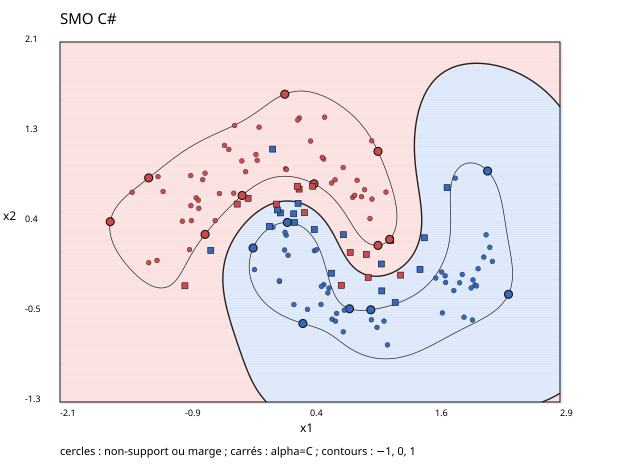

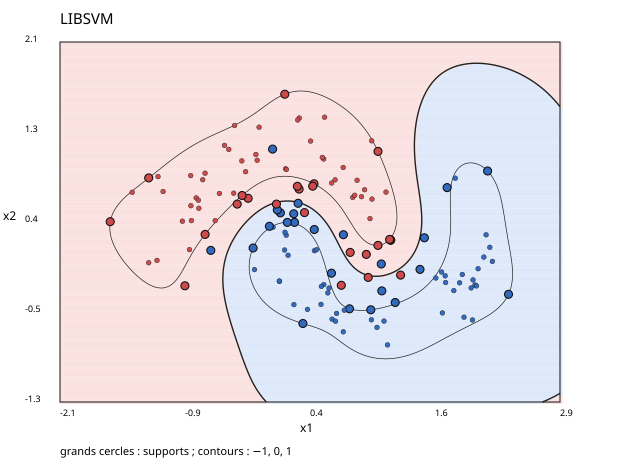

In [6]:
record SvmSvg(string Value);
Formatter.Register<SvmSvg>((value, writer) => writer.Write(value.Value), "image/svg+xml");
string DecisionPlot(string title, double[][] points, double[] labels, double[] alpha, double C, double[, ] score, double minX, double maxX, double minY, double maxY, bool sklearn)
{
    const int size = 200, left = 60, top = 42, width = 500, height = 360;
    double dx = width / (double)(size - 1), dy = height / (double)(size - 1);
    var svg = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='620' height='470' viewBox='0 0 620 470'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif'><text x='60' y='24' font-size='15'>{title}</text>");
    // Regrouper les cases consécutives de même signe sans réduire la grille 200×200.
    for (int row = 0; row < size; row++)
    {
        int start = 0;
        for (int col = 1; col <= size; col++)
        {
            if (col < size && (score[row, col] >= 0) == (score[row, start] >= 0))
                continue;
            string fill = score[row, start] >= 0 ? "#dce8fa" : "#fbe0e0";
            double x = left + start * dx, y = top + (size - 1 - row) * dy;
            svg.Append($"<rect x='{x:0.00}' y='{y:0.00}' width='{(col - start) * dx + 0.1:0.00}' height='{dy + 0.1:0.00}' fill='{fill}'/>");
            start = col;
        }
    }

    // Interpolation linéaire par cellule pour les contours f = -1, 0, +1.
    foreach (double level in new[]
    {
        -1.0,
        0.0,
        1.0
    }

    )
    {
        var path = new StringBuilder();
        for (int row = 0; row < size - 1; row++)
            for (int col = 0; col < size - 1; col++)
            {
                var intersections = new List<(double x, double y)>();
                var values = new[]
                {
                    score[row, col],
                    score[row, col + 1],
                    score[row + 1, col + 1],
                    score[row + 1, col]
                };
                var px = new[]
                {
                    (double)col,
                    col + 1.0,
                    col + 1.0,
                    (double)col
                };
                var py = new[]
                {
                    (double)row,
                    (double)row,
                    row + 1.0,
                    row + 1.0
                };
                for (int edge = 0; edge < 4; edge++)
                {
                    int next = (edge + 1) % 4;
                    if ((values[edge] < level) == (values[next] < level))
                        continue;
                    double t = (level - values[edge]) / (values[next] - values[edge]);
                    double vx = left + (px[edge] + t * (px[next] - px[edge])) * dx;
                    double vy = top + (size - 1 - (py[edge] + t * (py[next] - py[edge]))) * dy;
                    intersections.Add((vx, vy));
                }

                for (int i = 0; i + 1 < intersections.Count; i += 2)
                    path.Append($"M{intersections[i].x:0.00},{intersections[i].y:0.00}L{intersections[i + 1].x:0.00},{intersections[i + 1].y:0.00}");
            }

        svg.Append($"<path d='{path}' fill='none' stroke='#222' stroke-width='{(level == 0 ? 1.4 : 0.7):0.0}'/>");
    }

    for (int i = 0; i < points.Length; i++)
    {
        double px = left + (points[i][0] - minX) / (maxX - minX) * width;
        double py = top + (maxY - points[i][1]) / (maxY - minY) * height;
        string fill = labels[i] > 0 ? "#326ac0" : "#cf4b4b";
        bool support = alpha[i] > 1e-6, atBound = alpha[i] >= C - 1e-6;
        if (!sklearn && atBound)
            svg.Append($"<rect x='{px - 3:0.0}' y='{py - 3:0.0}' width='6' height='6' fill='{fill}' stroke='#111' stroke-width='.6'/>");
        else
            svg.Append($"<circle cx='{px:0.0}' cy='{py:0.0}' r='{(support ? 4 : 2.4):0.0}' fill='{fill}' stroke='#111' stroke-width='{(support ? 1.1 : .4):0.0}'/>");
    }

    // Repères numériques communs aux deux panneaux pour lire les coordonnées.
    for (int tick = 0; tick <= 4; tick++)
    {
        double fraction = tick / 4.0;
        double px = left + fraction * width;
        double py = top + (1 - fraction) * height;
        svg.Append($"<text x='{px:0.0}' y='416' font-size='9'>{minX + fraction * (maxX - minX):0.0}</text><text x='25' y='{py:0.0}' font-size='9'>{minY + fraction * (maxY - minY):0.0}</text>");
    }

    svg.Append($"<rect x='{left}' y='{top}' width='{width}' height='{height}' fill='none' stroke='#111'/><text x='300' y='432' font-size='12'>x1</text><text x='3' y='220' font-size='12'>x2</text><text x='60' y='455' font-size='11'>{(sklearn ? "grands cercles : supports" : "cercles : non-support ou marge ; carrés : alpha=C")} ; contours : −1, 0, 1</text></g></svg>");
    return svg.ToString();
}

double xmin = data.GetProperty("xmin").GetDouble(), xmax = data.GetProperty("xmax").GetDouble();
double ymin = data.GetProperty("ymin").GetDouble(), ymax = data.GetProperty("ymax").GetDouble();
var referenceGrid = Vector(data.GetProperty("grid_scores"));
var field = new double[200, 200];
var fieldSk = new double[200, 200];
for (int row = 0; row < 200; row++)
    for (int col = 0; col < 200; col++)
    {
        var point = new[]
        {
            xmin + (xmax - xmin) * col / 199.0,
            ymin + (ymax - ymin) * row / 199.0
        };
        field[row, col] = Smo.Score(point, train, ytrain, model.Alpha, model.Bias, 2);
        fieldSk[row, col] = referenceGrid[row * 200 + col];
    }

display(new SvmSvg(DecisionPlot("SMO C#", train, ytrain, model.Alpha, 1, field, xmin, xmax, ymin, ymax, false)), "image/svg+xml");
display(new SvmSvg(DecisionPlot("LIBSVM", train, ytrain, alphaSk, 1, fieldSk, xmin, xmax, ymin, ymax, true)), "image/svg+xml");

## 9. Comparer les supports et les scores

La sortie de la section 7 confronte le biais, les écarts de score en test et en entraînement, la fraction de prédictions identiques et le Jaccard des supports. Sur ce tirage, les sorties montrent 48 supports de chaque côté, une accuracy de test proche de 0,967 et un fort accord. Ces valeurs décrivent deux solutions arrêtées à tolérance finie ; elles n'établissent pas une égalité bit à bit ou une propriété universelle.

Un noyau RBF sur des points distincts peut fournir une Gram définie positive et une solution duale unique, mais cette hypothèse concerne le problème exact : deux trajectoires arrêtées avant l'optimum peuvent malgré tout différer.

## 10. Gap primal-dual et violations KKT

Pour le même α, la norme se reconstruit par `‖w‖²=(αy)ᵀK(αy)`. Le dual est `D=Σα−½‖w‖²` ; le primal vaut `P=½‖w‖²+C Σ max(0,1−yᵢfᵢ)`. Pour un α dualement faisable, la dualité faible donne `P−D≥0` et ce gap borne l'écart global à l'optimum. La sortie imprime aussi `Σαᵢyᵢ` pour contrôler la faisabilité.

La violation KKT additionne `max(0,1−yᵢfᵢ)` quand `αᵢ<C` et `max(0,yᵢfᵢ−1)` quand `αᵢ>0`. La somme est au plus `n×tol` **si** chaque violation ponctuelle est sous tol ; les arrêts par `eps` ou nombre de passes ne garantissent pas seuls cette hypothèse. La cellule imprime somme, maximum et `n×tol` pour permettre cette vérification. Le dual reconstruit de LIBSVM sert de contre-épreuve numérique, sans transformer l'accord en certificat d'égalité exacte.

Sur ce tirage, l’écart absolu moyen des scores de test vaut environ `0,00040`, le maximum test `0,00099` et le maximum train `0,00117`. Elle décrit ce tirage, pas une égalité exacte des fonctions.


In [7]:
var diagnostics = Smo.Diagnostics(train, ytrain, model.Alpha, model.Bias, 1, 2);
var diagnosticsSk = Smo.Diagnostics(train, ytrain, alphaSk, data.GetProperty("bias").GetDouble(), 1, 2);
Console.WriteLine($"SMO : dual={diagnostics.dual:F6}, primal={diagnostics.primal:F6}, gap={diagnostics.primal - diagnostics.dual:E3}");
Console.WriteLine($"Égalité={diagnostics.equality:E3}, KKT somme={diagnostics.violation:E3}, pire={diagnostics.worst:E3}, n×tol={train.Length * 1e-3:E3}");
Console.WriteLine($"Multiplicateurs : zéro={model.Alpha.Count(v => v <= 1e-6)}, intérieurs={model.Alpha.Count(v => v > 1e-6 && v < 1 - 1e-6)}, borne={model.Alpha.Count(v => v >= 1 - 1e-6)}");
Console.WriteLine($"LIBSVM : dual={diagnosticsSk.dual:F6}, écart dual={Math.Abs(diagnostics.dual - diagnosticsSk.dual):E3}");

SMO : dual=30.396087, primal=30.399758, gap=3.671E-003


Égalité=-8.882E-016, KKT somme=5.582E-003, pire=7.951E-004, n×tol=1.400E-001


Multiplicateurs : zéro=92, intérieurs=16, borne=32


LIBSVM : dual=30.396089, écart dual=2.165E-006


### Exercice 2 — Moyenner le biais

Pour chaque support intérieur, calculer `bᵢ=yᵢ−ΣⱼαⱼyⱼK(xᵢ,xⱼ)`, puis moyenner ces valeurs et mesurer l'accuracy de test avec ce biais. Comparer le résultat au biais de la SMO. S'il n'y a aucun support intérieur, retourner l'absence de moyenne et d'accuracy plutôt que calculer sur un ensemble vide ; le garde teste aussi ce cas.

In [8]:
(double? bias, double? accuracy) ExerciceBiais(double[][] x, double[] y, double[][] testX, double[] testY, SmoModel fit, double C, double gamma)
{
    // TODO : moyenner les biais calculés sur les supports intérieurs, puis évaluer le test.
    return (null, null);
}

var result = ExerciceBiais(train, ytrain, test, ytest, model, 1, 2);
var toyAnswer = ExerciceBiais(toyX, toyY, toyX, toyY, toy, 1, 1);
var absent = ExerciceBiais(toyX, toyY, toyX, toyY, new SmoModel(new double[toyY.Length], 0, 0), 1, 1);
if (result.bias == null && result.accuracy == null && toyAnswer.bias == null && toyAnswer.accuracy == null && absent.bias == null && absent.accuracy == null)
{
    Console.WriteLine("Exercice 2 à compléter.");
}
else if (result.bias == null || result.accuracy == null || toyAnswer.bias == null || toyAnswer.accuracy == null || absent.bias != null || absent.accuracy != null)
{
    Console.WriteLine("Exercice 2 : à revoir");
}
else
{
    var inside = Enumerable.Range(0, train.Length).Where(i => model.Alpha[i] > 1e-6 && model.Alpha[i] < 1 - 1e-6).ToArray();
    double expected = inside.Average(i => ytrain[i] - Smo.Score(train[i], train, ytrain, model.Alpha, 0, 2));
    double accuracy = test.Select((row, i) => Math.Sign(Smo.Score(row, train, ytrain, model.Alpha, expected, 2)) == ytest[i] ? 1.0 : 0.0).Average();
    var toyInside = Enumerable.Range(0, toyY.Length).Where(i => toy.Alpha[i] > 1e-6 && toy.Alpha[i] < 1 - 1e-6).ToArray();
    double toyBias = toyInside.Average(i => toyY[i] - Smo.Score(toyX[i], toyX, toyY, toy.Alpha, 0, 1));
    double toyAccuracy = toyX.Select((row, i) => Math.Sign(Smo.Score(row, toyX, toyY, toy.Alpha, toyBias, 1)) == toyY[i] ? 1.0 : 0.0).Average();
    bool ok = double.IsFinite(result.bias.Value) && double.IsFinite(result.accuracy.Value) && double.IsFinite(toyAnswer.bias.Value) && double.IsFinite(toyAnswer.accuracy.Value) && Math.Abs(result.bias.Value - expected) < 1e-9 && Math.Abs(result.accuracy.Value - accuracy) < 1e-10 && Math.Abs(toyAnswer.bias.Value - toyBias) < 1e-9 && Math.Abs(toyAnswer.accuracy.Value - toyAccuracy) < 1e-10;
    Console.WriteLine(ok ? "Exercice 2 : correct" : "Exercice 2 : à revoir");
}

Exercice 2 à compléter.


### Exercice 3 — Working set heuristique

Construire une variante qui sélectionne d'abord `i` parmi les violations puis choisit `j` parmi les multiplicateurs intérieurs ; conserver la mise à jour 2D et les mêmes tolérances/budgets. Comparer les examens, la frontière et le gap à la boucle de référence. Cette règle simplifiée n'est pas la sélection au second ordre complète de LIBSVM. Le garde vérifie faisabilité et diagnostics sur deux jeux ; il ne peut pas certifier à lui seul la stratégie employée ni juger la figure.

In [9]:
SmoModel ExerciceWorkingSet(double[][] x, double[] y, double C, double gamma, double tolerance, int maxPasses, double eps)
{
    // TODO : choisir une paire par l'heuristique demandée, mettre à jour le modèle et compter les examens.
    return null;
}

var result = ExerciceWorkingSet(toyX, toyY, 1, 1, 1e-4, 20, 1e-3);
var second = ExerciceWorkingSet(train, ytrain, 1, 2, 1e-3, 20, 1e-3);
if (result == null && second == null)
{
    Console.WriteLine("Exercice 3 à compléter.");
}
else if (result == null || second == null)
{
    Console.WriteLine("Exercice 3 : à revoir");
}
else
{
    bool Check(SmoModel candidate, double[][] x, double[] y, double gamma)
    {
        if (candidate == null || candidate.Alpha.Length != y.Length || candidate.Examinations <= 0 || candidate.Alpha.Any(v => !double.IsFinite(v) || v < -1e-9 || v > 1 + 1e-9))
            return false;
        var diagnostic = Smo.Diagnostics(x, y, candidate.Alpha, candidate.Bias, 1, gamma);
        return Math.Abs(diagnostic.equality) < 1e-7 && diagnostic.violation < .05 && diagnostic.primal - diagnostic.dual >= -1e-7 && diagnostic.primal - diagnostic.dual < .05;
    }

    bool ok = Check(result, toyX, toyY, 1) && Check(second, train, ytrain, 2);
    Console.WriteLine(ok ? $"Exercice 3 : modèles cohérents ; comparer les frontières, examens={second.Examinations}" : "Exercice 3 : à revoir");
}

Exercice 3 à compléter.


## 11. Bilan

| Élément | Ce qu'il apporte | Limite de lecture |
|---|---|---|
| Mise à jour 2D | conserve l'égalité du dual | point stationnaire à projeter ou bornes à comparer |
| Biais et cache | scores cohérents après chaque pas | un biais forcé à zéro peut décaler les marges |
| Supports et scores | comparaison plus fine que l'accuracy seule | accord arrondi ≠ identité exacte |
| Gap et KKT | diagnostics globaux et ponctuels | une somme nécessite de vérifier son hypothèse sur chaque point |
| Compteurs et temps | coût observé de chaque protocole | examens SMO et itérations LIBSVM ne sont pas la même unité |

La boucle C# est une implémentation explicite de la décomposition ; SVC donne une comparaison avec le vrai LIBSVM. Sur ce petit terrain les sorties concordent à leurs tolérances ; la précision et les temps restent propres aux données, budgets et environnements utilisés.

## À retenir

1. Deux multiplicateurs bougent ensemble pour préserver l'égalité du dual.
2. Le point stationnaire de la paire est contraint par la boîte ; à courbure nulle ou négative on examine les bornes.
3. Le biais décale tout le cache et se déduit des supports intérieurs lorsque ceux-ci existent.
4. L'accuracy, les scores, les supports, le gap et les KKT contrôlent des aspects distincts ; les conditions d'arrêt doivent être nommées.

## Vérifiez votre compréhension

**1. Pourquoi mettre à jour deux multiplicateurs ?**

<details><summary>Réponse</summary>Pour changer la solution tout en préservant la contrainte `Σαᵢyᵢ=0`.</details>

**2. Que signifient les multiplicateurs intérieurs ?**

<details><summary>Réponse</summary>À l'optimum exact, ils sont sur la marge et permettent notamment d'estimer le biais ; à tolérance finie on mesure l'écart.</details>

**3. Pourquoi comparer les scores au-delà de l'accuracy ?**

<details><summary>Réponse</summary>Deux scores peuvent avoir le même signe et donc la même prédiction tout en différant numériquement.</details>

**4. Que mesure le gap primal-dual ?**

<details><summary>Réponse</summary>Pour des points faisables, l'écart entre objectifs primal et dual borne la sous-optimalité ; la faisabilité et les tolérances doivent être vérifiées.</details>

## Pour aller plus loin

Le [notebook Python versionné](2.7b-SMO-From-Scratch.ipynb) est la source primaire de ce port ; [2.7c](2.7c-SVM-SOTA-Comparison-CSharp.ipynb) examine LIBSVM et son dual reconstruit.

### Références reprises de la source

1. Platt, J. C. (1998). *Sequential Minimal Optimization: A Fast Algorithm for Training Support Vector Machines*. MSR-TR-98-14, Microsoft Research.
2. Fan, R.-E., Chen, P.-H. & Lin, C.-J. (2005). *Working Set Selection Using Second Order Information for Training Support Vector Machines*. Journal of Machine Learning Research, 6, 1889–1918.
3. Cortes, C. & Vapnik, V. (1995). *Support-Vector Networks*. Machine Learning, 20(3), 273–297.
4. Vapnik, V. (1998). *Statistical Learning Theory*. Wiley.
5. Chang, C.-C. & Lin, C.-J. (2011). *LIBSVM: A Library for Support Vector Machines*. ACM Transactions on Intelligent Systems and Technology, 2(3), 27:1–27:27.
6. Boyd, S. & Vandenberghe, L. (2004). *Convex Optimization*. Cambridge University Press, §5.5.
7. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.
8. Deisenroth, M. P., Faisal, A. A. & Ong, C. S. (2020). *Mathematics for Machine Learning*. Cambridge University Press, ch. 12.

Ces références sont reprises de la source ; l'application des hypothèses de chaque résultat à ce tirage n'est pas supposée.